## Example of mid-point arbitrage

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
00: Expiry #0 1.0d: Generating extended strikes... removed 11 out of 128 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0: using 119 extended strikes based on 128 market strikes.


00: Expiry #0 1.0d: Could not hard fit with linear per-expiry no-arbitrage -- using masked soft fit instead which is outside bid/ask for 4 of 117 options. This took 0.066s.
00: Expiry #0 1.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 0.024s.
00: Expiry #0 1.0d: fit achived after removing 15 of 128 strikes.
00: Expiry #1 2.0d: Generating extended strikes... removed 9 out of 143 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0: using 136 extended strikes based on 143 market strikes.
00: Expiry #1 2.0d: Soft linear per-expiry no-arbitrage fit succeeded within bid/ask. This took 0.033s.
00: Expiry #2 2.2d: Generating extended strikes... removed 29 out of 291 strikes to ensure -1 < dC/dK[0] and dC/dK[-1] < 0: using 264 extended strikes based on 291 market strikes.
00: Expiry #2 2.2d: Could not hard fit with linear per-expiry no-arbitrage -- using masked soft fit instead which is outside bid/ask for 13 of 262 options. This took 0.26s.
00: Expiry #2 2.2d: C

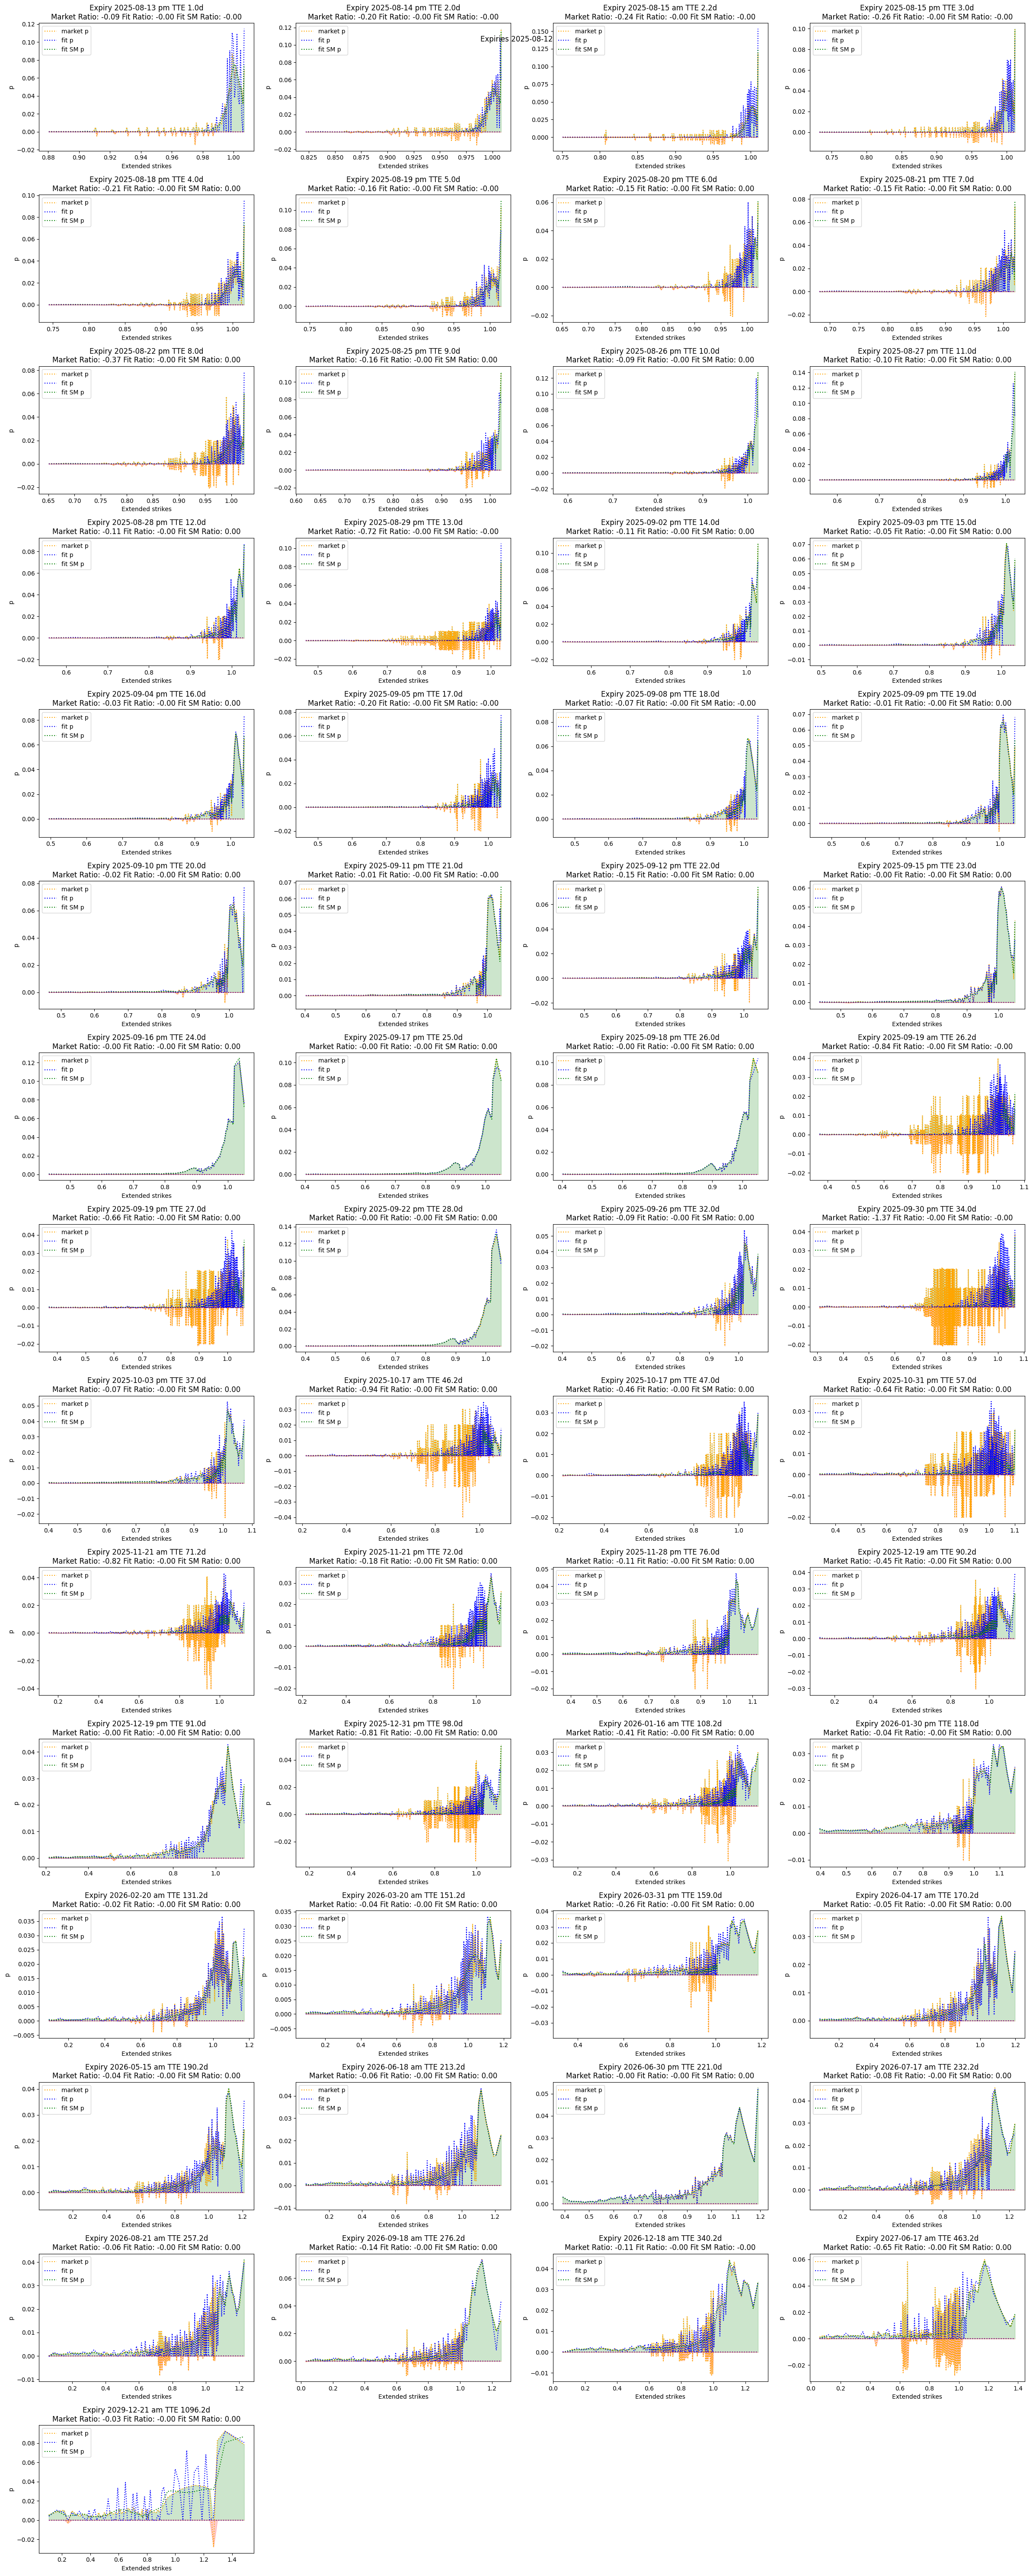

In [2]:
%load_ext autoreload
%autoreload 1

%aimport quantdata
%aimport quantdata.biz_calendar
%aimport quantdata.utils.arbfree
%aimport quantdata.widb
%aimport quantdata.widb.client
%aimport quantdata.widb.day
%aimport quantdata.widb.arbfree

from datetime import date

from cdxcore.dynaplot import figure
from cdxcore.pretty import PrettyObject
from quantdata.widb.day import collect_raw_day, enrich_day, ExpiryFilter, RawDayFilter
from quantdata.widb.options_filter import filter_options_day, OptionsFilter
from quantdata.widb.arbfree import mk_arb_free_day, MkArbFree
from quantdata.biz_calendar import next_business_day, DAYS_PER_YEAR
from cdxcore.verbose import Context
from IPython.display import display
import numpy as np

def test():
    ticker = "SPX"
    d      = next_business_day( date(2025, 8, 10), count_start=True )

    raw_day_filter = RawDayFilter()
    expiry_filter = ExpiryFilter()
    options_filter = OptionsFilter()
    verbose = Context.all

    raw_day  = collect_raw_day(ticker, d, raw_day_filter=raw_day_filter, verbose=verbose, raise_if_bad_day=False)
    day      = enrich_day(ticker, d, raw_day, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)
    #day      = filter_options_day(ticker, d, enr_day, options_filter=options_filter, mk_arb_free=None, raw_day_filter=raw_day_filter, expiry_filter=expiry_filter, verbose=verbose, raise_if_bad_day=False)
    
    # mk arb free
    r = PrettyObject()
    r.expiries = []
    r.expiry_id_str = []
    r.strikes = []
    r.asks = []
    r.bids = []
    r.nms_atm = []

    unids = np.unique( day['expiry_id'] )
    for uid in unids:
        mask = day['expiry_id'] == uid
        r.expiries.append( day['tte_y'][ mask ].iloc[0] )
        expiry = day['expiry'][ mask ].iloc[0]
        is_am = day['is_am'][ mask ].iloc[0]
        r.expiry_id_str.append( f"{expiry.date()} {'am' if is_am else 'pm'}" )

        strikes_t = day['pure_strike'][mask].to_numpy()
        ixs = np.argsort(strikes_t)
        r.strikes.append( strikes_t[ixs] )
        r.bids.append( day['pure_bid_price'][mask].to_numpy()[ixs] )
        r.asks.append( day['pure_ask_price'][mask].to_numpy()[ixs] )
        r.nms_atm.append( day['nms_atm'][mask].iloc[0] )

    r.expiries = np.array(r.expiries)
    T          = len(r.expiries)

    mkaf     = MkArbFree(smoothness=None,surface_expiry_linear=True, timeout_seconds=60.*20)
    af       = mkaf( r.expiries, r.strikes, r.bids, r.asks, verbose=Context(1) )
    mkaf    = MkArbFree(smoothness=0.1,surface_expiry_linear=True, timeout_seconds=60.*20)
    afSM     = mkaf( r.expiries, r.strikes, r.bids, r.asks, verbose=Context(1) )

    with figure(f"Expiries {d}", row_size=4, col_size=6, columns=4) as fig:
        for t in range(T):
            expiry_str = r.expiry_id_str[t]
            expiry     = r.expiries[t]
            strikes_t  = r.strikes[t]
            bids_t     = r.bids[t]
            asks_t     = r.asks[t]
            mids_t     = (bids_t + asks_t)/2.
            fits_t     = af.price( expiry, strikes_t, mode="surface" )
            fitsSM_t   = afSM.price( expiry, strikes_t, mode="surface" )

            strikesx = np.zeros((len(strikes_t)+2,), dtype=strikes_t.dtype)
            strikesx[1:-1] = strikes_t
            strikesx[0]    = strikes_t[0]*0.5
            strikesx[-1]   = strikes_t[-1]*1.5
            midx       = np.zeros_like(strikesx)
            midx[1:-1] = mids_t
            midx[0]    = 1.- strikesx[0]
            midx[-1]   = 0.
            fitx       = np.zeros_like(strikesx)
            fitx[1:-1] = fits_t
            fitx[0]    = 1.- strikesx[0]
            fitx[-1]   = 0.
            fitxSM       = np.zeros_like(strikesx)
            fitxSM[1:-1] = fitsSM_t
            fitxSM[0]    = 1.- strikesx[0]
            fitxSM[-1]   = 0.

            mdCdCK  = np.diff(midx,prepend=1.) / np.diff(strikesx,prepend=0.)
            mp      = np.diff(mdCdCK,append=0.) 
            mratio  = np.sum(mp[mp<0.]) / np.sum(mp)

            fdCdK  = np.diff(fitx,prepend=1.) / np.diff(strikesx,prepend=0.)
            fp     = np.diff(fdCdK,append=0.)
            fratio = np.sum(fp[fp<0.]) / np.sum(fp)

            fdCdKSM  = np.diff(fitxSM,prepend=1.) / np.diff(strikesx,prepend=0.)
            fpSM     = np.diff(fdCdKSM,append=0.)
            fratioSM = np.sum(fpSM[fpSM<0.]) / np.sum(fpSM)

            ax = fig.add_subplot(f"Expiry {expiry_str} TTE {expiry*DAYS_PER_YEAR:.1f}d\nMarket Ratio: {mratio:.2f} Fit Ratio: {fratio:.2f} Fit SM Ratio: {fratioSM:.2f}")
            ax.set_xlabel("Extended strikes")
            ax.plot(strikesx[1:-1], mp[1:-1], ":", label="market p", color="orange")
            ax.plot(strikesx[1:-1], fp[1:-1], ":", label="fit p", color="blue")
            ax.plot(strikesx[1:-1], fpSM[1:-1], ":", label="fit SM p", color="green")
            ax.fill_between(strikesx[1:-1], mp[1:-1]*0., np.clip(mp[1:-1], 0., None), color="green", alpha=0.2)
            ax.fill_between(strikesx[1:-1], np.clip(mp[1:-1],min=None,max=0.), mp[1:-1]*0., color="red", alpha=0.2)
            ax.plot(strikesx[1:-1], mp[1:-1]*0., ":", color="purple")
            ax.set_ylabel("p")
            ax.legend(loc="upper left")

    return r, af

r, af = test()

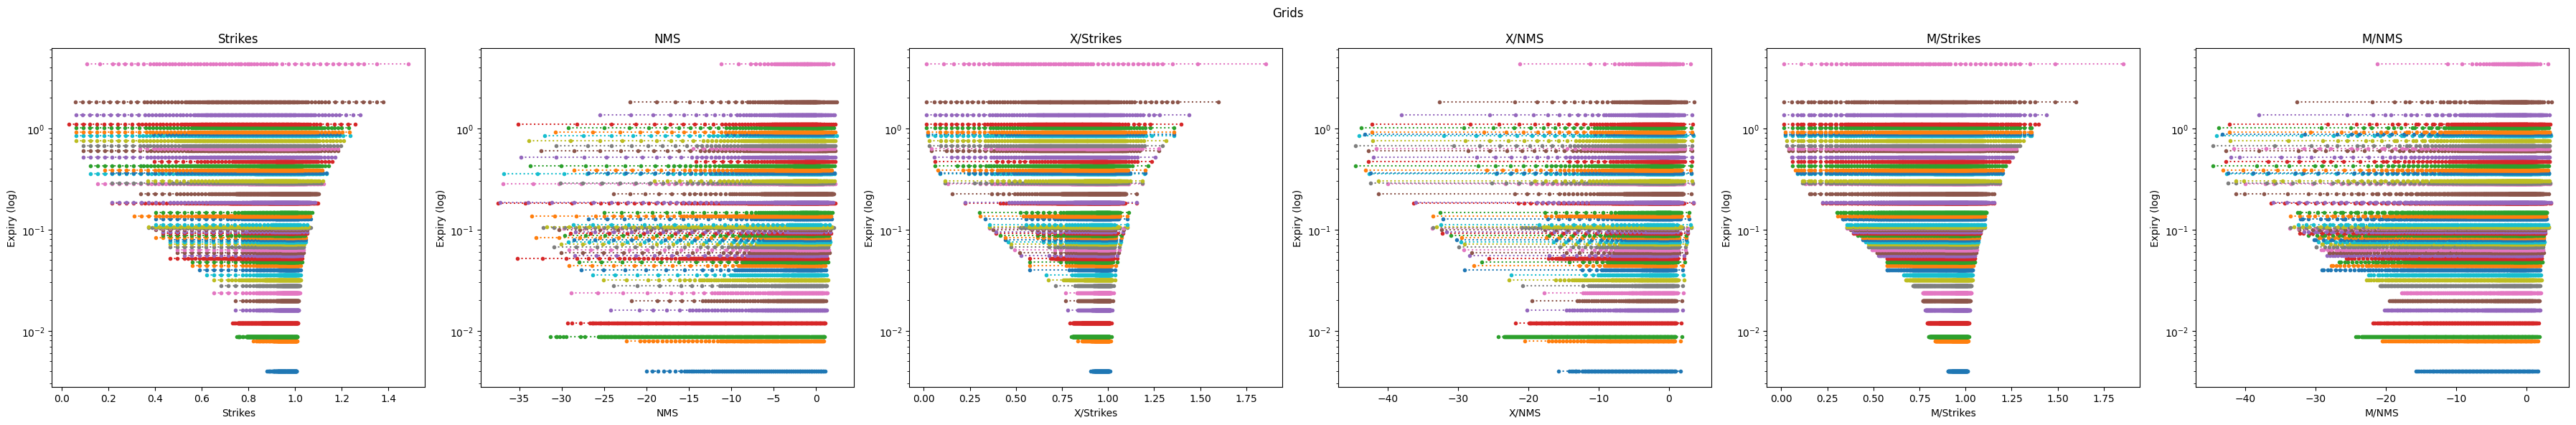

In [3]:
from quantdata.biz_calendar import NMS

def grids(r, af):
    with figure("Grids", row_size=6, col_size=6, columns=6) as fig:
        Taf = af.T
        axK = fig.add_subplot("Strikes")
        axN = fig.add_subplot("NMS")
        axXK = fig.add_subplot("X/Strikes")
        axXN = fig.add_subplot("X/NMS")
        axMK = fig.add_subplot("M/Strikes")
        axMN = fig.add_subplot("M/NMS")

        for t in range(af.T):
            expiry = af.expiries[t]
            nms    = NMS.to_nms( af.strikes[t], expiry )
            axK.plot( af.strikes[t], af.strikes[t]*0.+expiry, ".:")
            axN.plot( nms, nms*0.+expiry, ".:")

            xnms   = NMS.to_nms( af.xstrikes[t], expiry )
            axXK.plot( af.xstrikes[t], af.xstrikes[t]*0.+expiry, ".:")
            axXN.plot( xnms, xnms*0.+expiry, ".:")

            mnms   = NMS.to_nms( af.mstrikes[t], expiry )
            axMK.plot( af.mstrikes[t], af.mstrikes[t]*0.+expiry, ".:")
            axMN.plot( mnms, mnms*0.+expiry, ".:")

        axK.set_xlabel("Strikes")
        axK.set_ylabel("Expiry (log)")
        axK.set_yscale("log")
        axN.set_xlabel("NMS")
        axN.set_ylabel("Expiry (log)")
        axN.set_yscale("log")
        axXK.set_xlabel("X/Strikes")
        axXK.set_ylabel("Expiry (log)")
        axXK.set_yscale("log")
        axXN.set_xlabel("X/NMS")
        axXN.set_ylabel("Expiry (log)")
        axXN.set_yscale("log")
        axMK.set_xlabel("M/Strikes")
        axMK.set_ylabel("Expiry (log)")
        axMK.set_yscale("log")
        axMN.set_xlabel("M/NMS")
        axMN.set_ylabel("Expiry (log)")
        axMN.set_yscale("log")
        
grids(r,af)

